# HW1: Imitation Learning (Google Colab)

**上海交通大学 · 增强学习 · 2026 年秋季（Fall 2026）· 作业 1**

This notebook allows you to complete the entire HW1 assignment on Google Colab:
- **Part 0**: Environment setup (install dependencies, upload code)
- **Part 1**: Edit TODO code (guidance for the 3 files you need to modify)
- **Part 2**: Run training (Behavior Cloning & DAgger)
- **Part 3**: Visualize results (TensorBoard, plots, tables)
- **Part 4**: Download results

> **Tip:** Make sure to select a GPU runtime: `Runtime -> Change runtime type -> T4 GPU`
>
> See [colab_guide.md](colab_guide.md) for a detailed Colab usage guide.

课程平台与提交入口：[https://oc.sjtu.edu.cn/courses/95065](https://oc.sjtu.edu.cn/courses/95065)


---
## Part 0: Environment Setup

### 0.1 Install system dependencies

In [1]:
!apt-get update -qq
!apt-get install -y -qq xvfb > /dev/null 2>&1
print("System dependencies installed.")

'apt-get' �����ڲ����ⲿ���Ҳ���ǿ����еĳ���
���������ļ���


System dependencies installed.


ϵͳ�Ҳ���ָ����·����


### 0.2 Install Python dependencies

We install MuJoCo and other required packages. **We do NOT reinstall PyTorch** because Colab already has a CUDA-compatible version.

In [2]:
# mujoco==2.2.0 has no pre-built wheel for Colab's Python 3.10+;
# use mujoco>=2.3.0 which ships binary wheels compatible with Colab.
# tensorboardX is upgraded to 2.6.2.2: version 2.5.1 pins protobuf<=3.20.1
# and would downgrade Colab's native protobuf 6.x, breaking tensorboard and
# preinstalled Google libs. protobuf>=6.33.5,<7 satisfies Colab's preinstalled
# pb2 gencode (6.33.5) and is compatible with tensorboardX 2.6.2.2 (>=3.20).
!pip install "mujoco>=2.3.0" gym==0.25.2 tensorboardX==2.6.2.2 \
    moviepy==1.0.3 pyvirtualdisplay==3.0 opencv-python \
    "protobuf>=6.33.5,<7" ipdb swig -q
print("Python dependencies installed.")

Python dependencies installed.


### 0.3 Upload your code

Choose **one** of the two methods below:

- **Method A (Recommended):** Mount Google Drive (if you uploaded the `hw1` folder to Drive)
- **Method B:** Upload a zip file directly

In [ ]:
# ===== Method A: Mount Google Drive =====
# Uncomment the lines below if your hw1 folder is on Google Drive

# from google.colab import drive
# drive.mount('/content/drive')
# !cp -r /content/drive/MyDrive/path/to/hw1/* /content/
# print("Code copied from Google Drive.")

# ===== Method B: Upload zip file =====
# Uncomment the lines below to upload a zip file

# from google.colab import files
# uploaded = files.upload()  # Upload hw1.zip
# !unzip -o hw1.zip -d /content/ > /dev/null
# print("Code extracted from zip file.")

### 0.4 Install the project package

Make sure you are in the `hw1` directory and install the package in editable mode.

In [1]:
import os
# Change this path if your hw1 directory is at a different location
HW1_DIR = r'd:\Desktop\增强学习_95065_2026Fall_HW1-1'
os.chdir(HW1_DIR)
!pip install -e . -q
print(f"Working directory: {os.getcwd()}")

Working directory: d:\Desktop\增强学习_95065_2026Fall_HW1-1


### 0.5 Configure MuJoCo rendering & virtual display

In [9]:
import os
os.environ['MUJOCO_GL'] = 'egl'

from pyvirtualdisplay import Display
display = Display(visible=0, size=(1400, 900))
display.start()
print("Virtual display started.")

FileNotFoundError: [WinError 2] 系统找不到指定的文件。

### 0.6 Verify installation

Create a MuJoCo environment and check observation/action shapes.

In [2]:
import gym
import torch

env = gym.make('Ant-v4')
obs = env.reset()
print(f"Environment: Ant-v4")
print(f"Observation shape: {obs.shape}")
print(f"Action shape: {env.action_space.shape}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
env.close()
print("\nInstallation verified successfully!")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
d:\Anaconda3\envs\mass\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment: Ant-v4
Observation shape: (27,)
Action shape: (8,)
PyTorch version: 1.12.1+cpu
CUDA available: False

Installation verified successfully!


d:\Anaconda3\envs\mass\lib\site-packages\gym\core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
d:\Anaconda3\envs\mass\lib\site-packages\gym\wrappers\step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


### 0.7 NumPy 2.x compatibility patch (run once per session)

Colab's default NumPy 2.x removed `np.bool8`, which gym 0.25.2's passive env checker still references (`AttributeError: module 'numpy' has no attribute 'bool8'`). This patch restores the alias **without modifying any homework code**: a `sitecustomize.py` placed on `PYTHONPATH` is auto-imported by every Python process at startup.


In [ ]:
# One-time patch: restore np.bool8 for gym 0.25.2 under NumPy 2.x.
# The patch lives OUTSIDE the homework directory and does not modify any homework code.
!mkdir -p /content/pylib
!printf 'import numpy as _np\nif not hasattr(_np, "bool8"):\n    _np.bool8 = _np.bool_\n' > /content/pylib/sitecustomize.py
%env PYTHONPATH=/content/pylib
print("NumPy compatibility patch installed. Re-run this cell after any runtime restart.")


---
## Part 1: Edit TODO Code

You need to fill in the `TODO` sections in **3 files**:
1. `sjtuRL2026/infrastructure/utils.py` — trajectory sampling
2. `sjtuRL2026/policies/MLP_policy.py` — policy network forward & update
3. `sjtuRL2026/scripts/run_hw1.py` — training loop

**How to edit:** Use the Colab file browser on the left sidebar. Navigate to the file, double-click to open it in the editor, make your changes, and save with `Ctrl+S`.

### 1.1 `utils.py` — Trajectory Sampling

In `sample_trajectory()`, you need to:
1. Get an action from the policy: `policy.get_action(ob)`
2. Step the environment: `env.step(ac)`
3. Determine when a rollout is done (episode ends or max path length reached)

Below we display the relevant code section for reference:

In [ ]:
# Display the TODO section in utils.py
with open('sjtuRL2026/infrastructure/utils.py', 'r') as f:
    lines = f.readlines()
print("=== sjtuRL2026/infrastructure/utils.py (lines 16-67) ===")
for i, line in enumerate(lines[15:67], start=16):
    print(f"{i:4d} | {line}", end='')

### 1.2 `MLP_policy.py` — Policy Network

In `MLPPolicySL`, you need to implement:
1. `forward()` — Pass observation through `self.mean_net`, return a `distributions.Normal` distribution
2. `update()` — Compute MSE loss between sampled actions and expert actions, backpropagate

In [ ]:
# Display the TODO section in MLP_policy.py
with open('sjtuRL2026/policies/MLP_policy.py', 'r') as f:
    lines = f.readlines()
print("=== sjtuRL2026/policies/MLP_policy.py (lines 125-175) ===")
for i, line in enumerate(lines[124:175], start=125):
    print(f"{i:4d} | {line}", end='')

### 1.3 `run_hw1.py` — Training Loop

In `run_training_loop()`, you need to:
1. Collect transitions using `utils.sample_trajectories()`
2. Relabel collected observations with expert actions (for DAgger)
3. Sample a batch from the replay buffer for training

In [ ]:
# Display the TODO section in run_hw1.py
with open('sjtuRL2026/scripts/run_hw1.py', 'r') as f:
    lines = f.readlines()
print("=== sjtuRL2026/scripts/run_hw1.py (lines 125-170) ===")
for i, line in enumerate(lines[124:170], start=125):
    print(f"{i:4d} | {line}", end='')

### 1.4 Verify your edits

After editing all 3 files, run the cell below to check for syntax errors.

In [ ]:
# Verify imports (will fail if there are syntax errors)
import importlib
import sjtuRL2026.infrastructure.utils
importlib.reload(sjtuRL2026.infrastructure.utils)
import sjtuRL2026.policies.MLP_policy
importlib.reload(sjtuRL2026.policies.MLP_policy)
import sjtuRL2026.scripts.run_hw1
importlib.reload(sjtuRL2026.scripts.run_hw1)
print("All modules imported successfully! No syntax errors.")

---
## Part 2: Run Training

> **Tip:** Keep `--video_log_freq -1` while debugging to speed up experiments. Remove it to save videos of your trained policy.

### 2.1 Section 1: Behavior Cloning (BC)

Run BC on the Ant-v4 environment. This trains for 1 iteration using expert demonstration data.

In [3]:
!python sjtuRL2026/scripts/run_hw1.py \
    --expert_policy_file sjtuRL2026/policies/experts/Ant.pkl \
    --env_name Ant-v4 \
    --exp_name bc_ant \
    --n_iter 1 \
    --expert_data sjtuRL2026/expert_data/expert_data_Ant-v4.pkl \
    --video_log_freq -1

########################
logging outputs to  D:\Desktop\增强学习_95065_2026Fall_HW1-1\sjtuRL2026\scripts\../../data\q1_bc_ant_Ant-v4_07-10-2026_17-53-30
########################
GPU not detected. Defaulting to CPU.
Loading expert policy from... sjtuRL2026/policies/experts/Ant.pkl
obs (1, 111) (1, 111)
Done restoring expert policy...


********** Iteration 0 ************


Training agent using sampled data from replay buffer...

Beginning logging procedure...

Eval_AverageReturn : 889.3585205078125
Eval_StdReturn : 0.0
Eval_MaxReturn : 889.3585205078125
Eval_MinReturn : 889.3585205078125
Eval_AverageEpLen : 1000.0
Train_AverageReturn : 4681.891673935816
Train_StdReturn : 30.70862278765526
Train_MaxReturn : 4712.600296723471
Train_MinReturn : 4651.18305114816
Train_AverageEpLen : 1000.0
Training Loss : 0.03868952766060829
Train_EnvstepsSoFar : 0
TimeSinceStart : 1.4617457389831543
Initial_DataCollection_AverageReturn : 4681.891673935816
Done logging...




Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
d:\Anaconda3\envs\mass\lib\site-packages\gym\core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
d:\Anaconda3\envs\mass\lib\site-packages\gym\wrappers\step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
d:\Anaconda3\envs\mass\lib\site-p

You should also try at least one more environment. Uncomment and modify one of the commands below:

In [4]:
# Uncomment ONE of these to try another environment:

!python sjtuRL2026/scripts/run_hw1.py \
    --expert_policy_file sjtuRL2026/policies/experts/HalfCheetah.pkl \
    --env_name HalfCheetah-v4 \
    --exp_name bc_halfcheetah \
    --n_iter 1 \
    --expert_data sjtuRL2026/expert_data/expert_data_HalfCheetah-v4.pkl \
    --video_log_freq -1

# !python sjtuRL2026/scripts/run_hw1.py \
#     --expert_policy_file sjtuRL2026/policies/experts/Hopper.pkl \
#     --env_name Hopper-v4 \
#     --exp_name bc_hopper \
#     --n_iter 1 \
#     --expert_data sjtuRL2026/expert_data/expert_data_Hopper-v4.pkl \
#     --video_log_freq -1

# !python sjtuRL2026/scripts/run_hw1.py \
#     --expert_policy_file sjtuRL2026/policies/experts/Walker2d.pkl \
#     --env_name Walker2d-v4 \
#     --exp_name bc_walker2d \
#     --n_iter 1 \
#     --expert_data sjtuRL2026/expert_data/expert_data_Walker2d-v4.pkl \
#     --video_log_freq -1

########################
logging outputs to  D:\Desktop\增强学习_95065_2026Fall_HW1-1\sjtuRL2026\scripts\../../data\q1_bc_halfcheetah_HalfCheetah-v4_07-10-2026_17-53-36
########################
GPU not detected. Defaulting to CPU.
Loading expert policy from... sjtuRL2026/policies/experts/HalfCheetah.pkl
obs (1, 17) (1, 17)
Done restoring expert policy...


********** Iteration 0 ************


Training agent using sampled data from replay buffer...

Beginning logging procedure...

Eval_AverageReturn : 3227.26513671875
Eval_StdReturn : 0.0
Eval_MaxReturn : 3227.26513671875
Eval_MinReturn : 3227.26513671875
Eval_AverageEpLen : 1000.0
Train_AverageReturn : 4034.7999834965067
Train_StdReturn : 32.8677631311341
Train_MaxReturn : 4067.6677466276406
Train_MinReturn : 4001.9322203653724
Train_AverageEpLen : 1000.0
Training Loss : 0.04402244836091995
Train_EnvstepsSoFar : 0
TimeSinceStart : 1.0969295501708984
Initial_DataCollection_AverageReturn : 4034.7999834965067
Done logging...




Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
d:\Anaconda3\envs\mass\lib\site-packages\gym\core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
d:\Anaconda3\envs\mass\lib\site-packages\gym\wrappers\step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
d:\Anaconda3\envs\mass\lib\site-p

### 2.2 Section 2: DAgger

Run DAgger on the Ant-v4 environment. Note the `--do_dagger` flag and higher `--n_iter`.

In [5]:
!python sjtuRL2026/scripts/run_hw1.py \
    --expert_policy_file sjtuRL2026/policies/experts/Ant.pkl \
    --env_name Ant-v4 \
    --exp_name dagger_ant \
    --n_iter 10 \
    --do_dagger \
    --expert_data sjtuRL2026/expert_data/expert_data_Ant-v4.pkl \
    --video_log_freq -1

########################
logging outputs to  D:\Desktop\增强学习_95065_2026Fall_HW1-1\sjtuRL2026\scripts\../../data\q2_dagger_ant_Ant-v4_07-10-2026_17-53-48
########################
GPU not detected. Defaulting to CPU.
Loading expert policy from... sjtuRL2026/policies/experts/Ant.pkl
obs (1, 111) (1, 111)
Done restoring expert policy...


********** Iteration 0 ************


Training agent using sampled data from replay buffer...

Beginning logging procedure...

Eval_AverageReturn : 889.3585205078125
Eval_StdReturn : 0.0
Eval_MaxReturn : 889.3585205078125
Eval_MinReturn : 889.3585205078125
Eval_AverageEpLen : 1000.0
Train_AverageReturn : 4681.891673935816
Train_StdReturn : 30.70862278765526
Train_MaxReturn : 4712.600296723471
Train_MinReturn : 4651.18305114816
Train_AverageEpLen : 1000.0
Training Loss : 0.03868952766060829
Train_EnvstepsSoFar : 0
TimeSinceStart : 1.4118332862854004
Initial_DataCollection_AverageReturn : 4681.891673935816
Done logging...




********** Iteration 1 ********

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
d:\Anaconda3\envs\mass\lib\site-packages\gym\core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
d:\Anaconda3\envs\mass\lib\site-packages\gym\wrappers\step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
d:\Anaconda3\envs\mass\lib\site-p

---
## Part 3: Visualize Results

### 3.0 TensorBoard (inline)

You can use TensorBoard directly in Colab to explore your results interactively.

In [7]:
%pip install "tensorboard==2.12.3"

  Using cached tensorboard_data_server-0.7.2-py3-none-any.whl.metadata (1.1 kB)
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached requests_oauthlib-2.0.0-py2.py3-none-any.whl.metadata (11 kB)
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.6 MB ? eta -:--:--
   ----------

In [8]:
%load_ext tensorboard
%tensorboard --logdir data

Launching TensorBoard...

### 3.1 Load event data

In [9]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import matplotlib.pyplot as plt
import numpy as np
import os

log_dir = 'data'
run_folders = [os.path.join(log_dir, run) for run in os.listdir(log_dir)
               if os.path.isdir(os.path.join(log_dir, run))]
print(f"Found {len(run_folders)} runs in {log_dir}")
for f in run_folders:
    print(f"  {os.path.basename(f)}")

d:\Anaconda3\envs\mass\lib\site-packages\matplotlib\fontconfig_pattern.py:66: PyparsingDeprecationWarning: 'setParseAction' deprecated - use 'set_parse_action'
  ).setParseAction(self._family)
d:\Anaconda3\envs\mass\lib\site-packages\matplotlib\fontconfig_pattern.py:127: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  self._parser.parseString(pattern)
d:\Anaconda3\envs\mass\lib\site-packages\matplotlib\fontconfig_pattern.py:134: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  self._parser.resetCache()
d:\Anaconda3\envs\mass\lib\site-packages\matplotlib\_mathtext.py:30: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
  ParserElement.enablePackrat()
In d:\Anaconda3\envs\mass\lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: 'parseString' deprecated - use 'parse_string'
In d:\Anaconda3\envs\mass\lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: 'resetCache' deprecated - use

Found 7 runs in data
  q1_bc_ant_Ant-v4_01-10-2026_14-18-57
  q1_bc_ant_Ant-v4_07-10-2026_17-53-30
  q1_bc_ant_smoke_Ant-v4_01-10-2026_14-18-36
  q1_bc_halfcheetah_HalfCheetah-v4_07-10-2026_17-53-36
  q1_compat_check_Ant-v4_01-10-2026_15-06-26
  q2_dagger_ant_Ant-v4_07-10-2026_17-53-48
  q2_dagger_ant_smoke_Ant-v4_01-10-2026_14-19-23


### 3.2 BC Results Table

Report mean and std of evaluation returns for your BC experiments.

In [10]:
bc_runs = [f for f in run_folders if os.path.basename(f).startswith('q1_')]
print(f"BC runs: {[os.path.basename(f) for f in bc_runs]}")

BC runs: ['q1_bc_ant_Ant-v4_01-10-2026_14-18-57', 'q1_bc_ant_Ant-v4_07-10-2026_17-53-30', 'q1_bc_ant_smoke_Ant-v4_01-10-2026_14-18-36', 'q1_bc_halfcheetah_HalfCheetah-v4_07-10-2026_17-53-36', 'q1_compat_check_Ant-v4_01-10-2026_15-06-26']


In [11]:
# Print BC results table
print(f"{'Run Name':<50} {'Eval Mean':>12} {'Eval Std':>12}")
print("-" * 76)
for run_folder in bc_runs:
    event_acc = EventAccumulator(run_folder)
    event_acc.Reload()

    try:
        eval_avg = event_acc.Scalars('Eval_AverageReturn')
        eval_std = event_acc.Scalars('Eval_StdReturn')
        if not eval_avg:
            continue
        name = os.path.basename(run_folder)
        print(f"{name:<50} {eval_avg[-1].value:>12.2f} {eval_std[-1].value:>12.2f}")
    except Exception as e:
        print(f"Could not read {os.path.basename(run_folder)}: {e}")


Run Name                                              Eval Mean     Eval Std
----------------------------------------------------------------------------
q1_bc_ant_Ant-v4_01-10-2026_14-18-57                    1018.90         0.00
q1_bc_ant_Ant-v4_07-10-2026_17-53-30                     889.36         0.00
q1_bc_ant_smoke_Ant-v4_01-10-2026_14-18-36              -226.87       103.09
q1_bc_halfcheetah_HalfCheetah-v4_07-10-2026_17-53-36      3227.27         0.00
q1_compat_check_Ant-v4_01-10-2026_15-06-26              -126.50        64.41


### 3.3 BC Hyperparameter Experiment

Plot BC performance vs. a chosen hyperparameter (e.g., training steps, data amount, network size).

Modify the filter condition below to match your experiment naming convention.

In [12]:
bc_hyp_runs = [f for f in bc_runs if 'bc_ant' in os.path.basename(f).lower()]

In [14]:
%pip install "matplotlib-inline==0.1.7"

  Attempting uninstall: matplotlib-inline
    Found existing installation: matplotlib-inline 0.2.2
    Uninstalling matplotlib-inline-0.2.2:
      Successfully uninstalled matplotlib-inline-0.2.2
Note: you may need to restart the kernel to use updated packages.


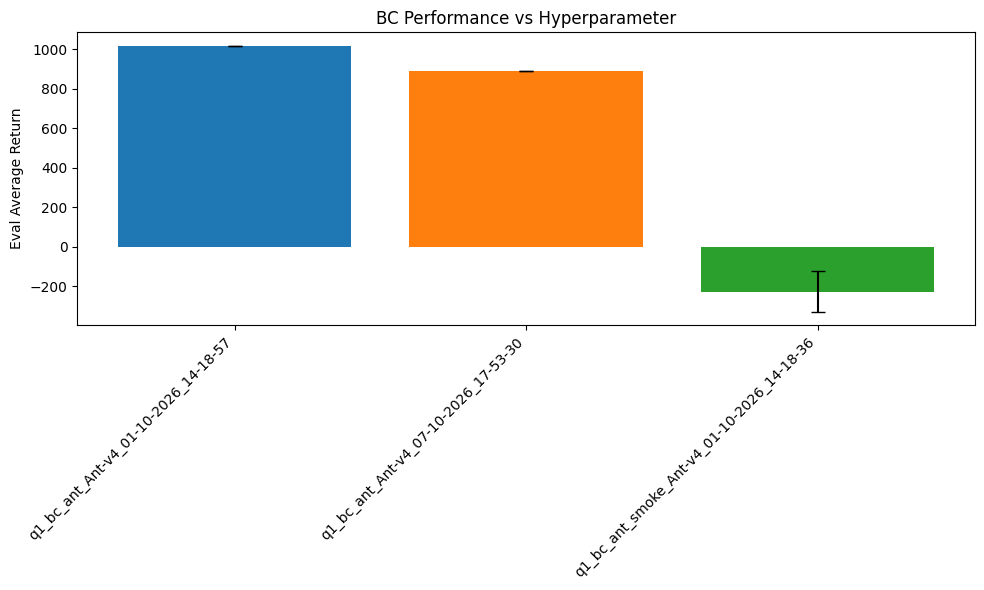

In [15]:
plt.figure(figsize=(10, 6))

for run_folder in bc_hyp_runs:
    event_acc = EventAccumulator(run_folder)
    event_acc.Reload()

    try:
        eval_avg = event_acc.Scalars('Eval_AverageReturn')
        eval_std = event_acc.Scalars('Eval_StdReturn')
        if not eval_avg:
            continue
        label = os.path.basename(run_folder)
        plt.bar(label, eval_avg[-1].value, yerr=eval_std[-1].value, capsize=5)
    except Exception as e:
        print(f"Could not read {os.path.basename(run_folder)}: {e}")

plt.ylabel('Eval Average Return')
plt.title('BC Performance vs Hyperparameter')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### 3.4 DAgger Learning Curve

Plot DAgger iteration vs. average return, with expert and BC baselines.

In [16]:
dagger_runs = [f for f in run_folders if os.path.basename(f).startswith('q2_')]
print(f"DAgger runs: {[os.path.basename(f) for f in dagger_runs]}")

DAgger runs: ['q2_dagger_ant_Ant-v4_07-10-2026_17-53-48', 'q2_dagger_ant_smoke_Ant-v4_01-10-2026_14-19-23']


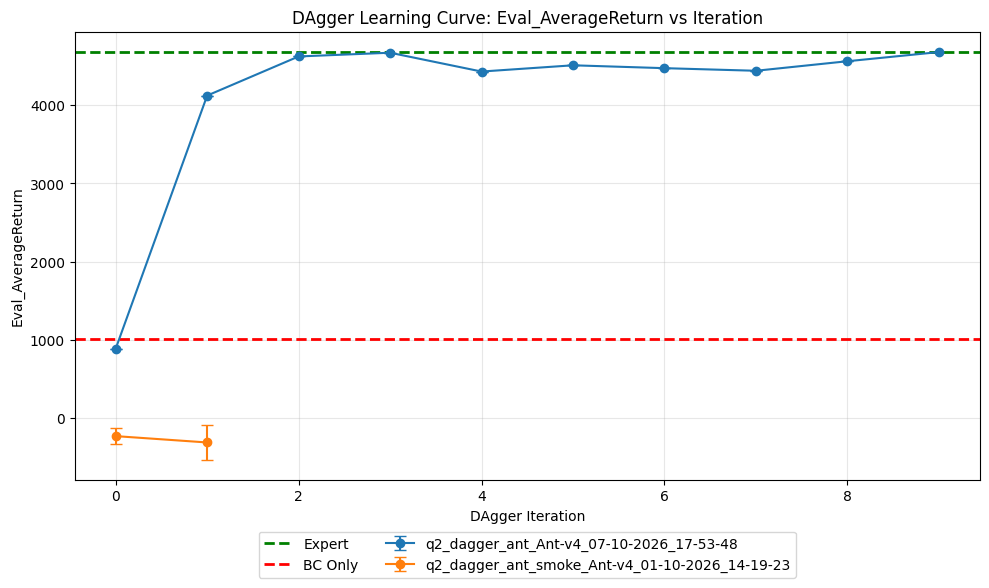

In [17]:
plt.figure(figsize=(10, 6))

for run_folder in dagger_runs:
    event_acc = EventAccumulator(run_folder)
    event_acc.Reload()

    try:
        eval_scalars = event_acc.Scalars('Eval_AverageReturn')
        std_scalars = event_acc.Scalars('Eval_StdReturn')
        if not eval_scalars:
            continue
        steps = [s.step for s in eval_scalars]
        eval_avg = [s.value for s in eval_scalars]
        eval_std = [s.value for s in std_scalars]
        plt.errorbar(steps, eval_avg, yerr=eval_std, marker='o', capsize=4,
                     label=os.path.basename(run_folder))
    except Exception as e:
        print(f"Could not retrieve data for {run_folder}: {e}")

# Expert baseline: Train_AverageReturn of the BC run (= return of expert data)
expert_return = None
for f in bc_runs:
    acc = EventAccumulator(f)
    acc.Reload()
    try:
        expert_return = acc.Scalars('Train_AverageReturn')[-1].value
        break
    except Exception:
        pass
if expert_return is not None:
    plt.axhline(y=expert_return, color='g', linestyle='--', linewidth=2, label='Expert')

# BC baseline: final Eval_AverageReturn of the BC run
bc_return = None
for f in bc_runs:
    acc = EventAccumulator(f)
    acc.Reload()
    try:
        bc_return = acc.Scalars('Eval_AverageReturn')[-1].value
        break
    except Exception:
        pass
if bc_return is not None:
    plt.axhline(y=bc_return, color='r', linestyle='--', linewidth=2, label='BC Only')

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.xlabel('DAgger Iteration')
plt.ylabel('Eval_AverageReturn')
plt.title('DAgger Learning Curve: Eval_AverageReturn vs Iteration')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 3.5 Training Loss

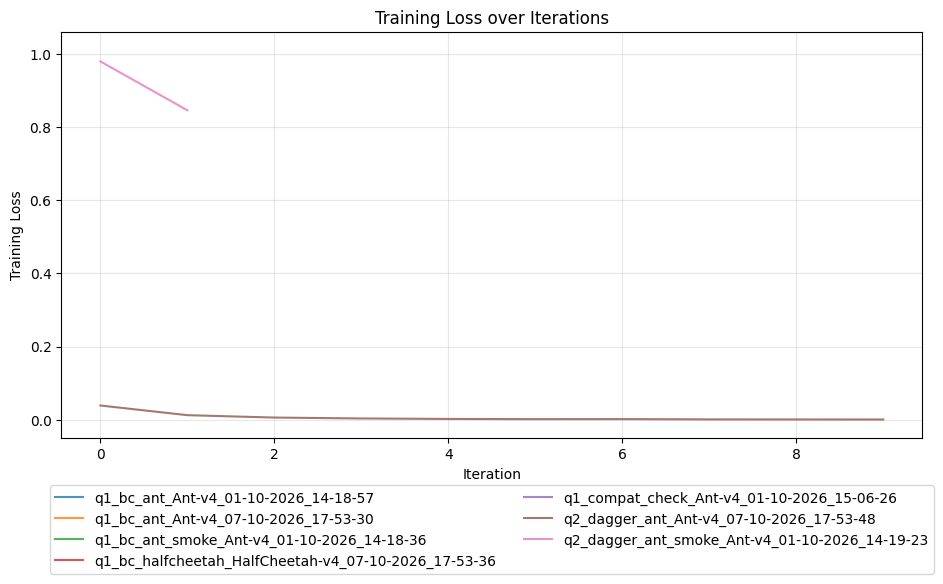

In [18]:
plt.figure(figsize=(10, 6))

all_runs = bc_runs + dagger_runs
for run_folder in all_runs:
    event_acc = EventAccumulator(run_folder)
    event_acc.Reload()

    try:
        loss_scalars = event_acc.Scalars('Training_Loss')
        if not loss_scalars:
            continue
        steps = [s.step for s in loss_scalars]
        values = [s.value for s in loss_scalars]
        plt.plot(steps, values, alpha=0.8, label=os.path.basename(run_folder))
    except Exception as e:
        print(f"Could not read Training_Loss for {os.path.basename(run_folder)}: {e}")

plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=2)
plt.xlabel('Iteration')
plt.ylabel('Training Loss')
plt.title('Training Loss over Iterations')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 3.6 BC vs DAgger Comparison Table

In [19]:
print(f"{'Run Name':<50} {'Type':<8} {'Eval Mean':>12} {'Eval Std':>12}")
print("-" * 84)

for run_folder in all_runs:
    event_acc = EventAccumulator(run_folder)
    event_acc.Reload()

    try:
        eval_avg = np.array([s.value for s in event_acc.Scalars('Eval_AverageReturn')])
        eval_std = np.array([s.value for s in event_acc.Scalars('Eval_StdReturn')])
        name = os.path.basename(run_folder)
        run_type = 'BC' if name.startswith('q1_') else 'DAgger'
        print(f"{name:<50} {run_type:<8} {eval_avg[-1]:>12.2f} {eval_std[-1]:>12.2f}")
    except Exception as e:
        print(f"Could not read {os.path.basename(run_folder)}: {e}")

Run Name                                           Type        Eval Mean     Eval Std
------------------------------------------------------------------------------------
q1_bc_ant_Ant-v4_01-10-2026_14-18-57               BC            1018.90         0.00
q1_bc_ant_Ant-v4_07-10-2026_17-53-30               BC             889.36         0.00
q1_bc_ant_smoke_Ant-v4_01-10-2026_14-18-36         BC            -226.87       103.09
q1_bc_halfcheetah_HalfCheetah-v4_07-10-2026_17-53-36 BC            3227.27         0.00
q1_compat_check_Ant-v4_01-10-2026_15-06-26         BC            -126.50        64.41
q2_dagger_ant_Ant-v4_07-10-2026_17-53-48           DAgger        4676.49         0.00
q2_dagger_ant_smoke_Ant-v4_01-10-2026_14-19-23     DAgger        -307.88       217.79


---
## Part 4: Download Results

Download the `data/` directory as a personal backup; do not submit this ZIP. Fill in `hw1_template.tex`, compile with XeLaTeX, and submit only the resulting PDF report.

In [20]:
import shutil
shutil.make_archive('hw1_results', 'zip', '.', 'data')
print("Created hw1_results.zip")

# Download the zip file (only works in Colab)
try:
    from google.colab import files
    files.download('hw1_results.zip')
except ImportError:
    print("Not running in Colab. Find hw1_results.zip in the current directory.")

Created hw1_results.zip
Not running in Colab. Find hw1_results.zip in the current directory.


> **Reminder:** Download your TensorBoard logs (`data/` folder) and any generated plots before closing this Colab session. Colab runtime storage is temporary!